# Лабораторная работа №4. Глубокое обучение и трансформеры в анализе текстов

Тема: дистрибутивная семантика (Word2Vec), рекуррентные сети (BiLSTM), дообучение предобученного трансформера и сводный бенчмарк всех методов курса.

Датасет тот же, что в лабораторных 1-3: AG News, 120 000 новостей четырёх классов (World, Sports, Business, Sci/Tech). Разбиение на Train и Test такое же: 80 на 20, стратифицированное, `random_state=42`. Поэтому результаты классических моделей из третьей работы напрямую сравнимы с новыми.

План работы:
1. Word2Vec на Train: ближайшие слова для пяти ключевых слов и карта t-SNE.
2. Baseline: усреднение векторов слов (mean pooling) и логистическая регрессия.
3. BiLSTM в двух режимах слоя Embedding: static (веса Word2Vec заморожены) и dynamic (обучается с нуля).
4. Оценка RNN: графики Loss и F1 по эпохам, Early Stopping, метрики на Test.
5. Выбор предобученного трансформера.
6. Fine-Tuning трансформера и метрики на Test.
7. Сводный бенчмарк: Naive Bayes, SVM, логистическая регрессия, BiLSTM, трансформер.
8. Итоговый вывод.

In [1]:
import re, html, math, time, copy, unicodedata, warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from gensim.models import Word2Vec

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, classification_report

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Устройство для PyTorch:', DEVICE)

results = {}   # сюда собираются метрики всех моделей для итоговой таблицы


def evaluate(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')
    return {'precision': p, 'recall': r, 'f1': f, 'accuracy': accuracy_score(y_true, y_pred)}

Устройство для PyTorch: cpu


## 0. Данные и предобработка

Загружаю AG News и делаю то же разбиение, что в предыдущих работах. Если Hugging Face недоступен, ячейка берёт тот же датасет в виде CSV с GitHub.

In [2]:
LABEL_MAP = {1: 'World', 2: 'Sports', 3: 'Business', 4: 'Sci/Tech'}

try:
    from datasets import load_dataset
    raw = load_dataset('fancyzhx/ag_news')
    df = pd.DataFrame(raw['train'])
    df['label'] = df['label'] + 1
    source = 'Hugging Face'
except Exception as e:
    URL = 'https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/train.csv'
    df = pd.read_csv(URL, header=None, names=['label', 'title', 'description'])
    df['text'] = df['title'] + ' ' + df['description']
    source = 'GitHub CSV (запасной источник)'

df['category'] = df['label'].map(LABEL_MAP)

train_df, test_df = train_test_split(
    df[['text', 'label', 'category']], test_size=0.2,
    random_state=RANDOM_STATE, stratify=df['label'])
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print('Источник:', source)
print('Train:', train_df.shape, ' Test:', test_df.shape)
print('Среднее число слов в Train:', round(train_df['text'].str.split().str.len().mean(), 1))
print('Первый документ Train:', train_df['text'].iloc[0][:90])
print()
print(pd.concat([train_df['category'].value_counts().rename('Train'),
                 test_df['category'].value_counts().rename('Test')], axis=1))

Источник: GitHub CSV (запасной источник)
Train: (96000, 3)  Test: (24000, 3)


Среднее число слов в Train: 37.9
Первый документ Train: Clijsters Unsure About Latest Injury, Says Hewitt  TOKYO (Reuters) - Belgian Kim Clijsters

          Train  Test
category             
Sports    24000  6000
Sci/Tech  24000  6000
World     24000  6000
Business  24000  6000


Для Word2Vec и рекуррентной сети нужен очищенный текст в виде списка токенов. Использую ту же функцию `tokenize`, что в третьей лабораторной: правила очистки из первой работы, нижний регистр, без знаков препинания, числа, ссылки и почта заменены на слова `num`, `url`, `email`.

In [3]:
RE_HTML_TAG = re.compile(r'<[^>]+>')
RE_ENTITY_NO_AMP = re.compile(r'(?<![&\w])(#\d+|#x[0-9a-fA-F]+|quot|amp|lt|gt|apos);')
RE_URL = re.compile(r'https?://\S+|www\.\S+', re.IGNORECASE)
RE_EMAIL = re.compile(r'\b[A-Za-z0-9._%+\-]+@[A-Za-z0-9.\-]+\.[A-Za-z]{2,}\b')
RE_NUMBER = re.compile(r'(?<![A-Za-z\-.,])\b\d+([.,]\d+)*\b(?![A-Za-z\-])')
RE_BACKSLASH = re.compile(r'\\+')
RE_TOKEN = re.compile(r'\[(?:NUM|URL|EMAIL)\]|\w+(?:[-.]\w+)*|[^\w\s]')
SERVICE = {'[NUM]': 'num', '[URL]': 'url', '[EMAIL]': 'email'}


def tokenize(text):
    """Очистка из лабораторной 1 + нижний регистр, без знаков препинания."""
    text = RE_ENTITY_NO_AMP.sub(r'&\1;', text)
    text = html.unescape(text)
    text = RE_HTML_TAG.sub(' ', text)
    text = RE_URL.sub('[URL]', text)
    text = RE_EMAIL.sub('[EMAIL]', text)
    text = unicodedata.normalize('NFKD', text).encode('ascii', errors='ignore').decode('ascii')
    text = RE_NUMBER.sub('[NUM]', text)
    text = RE_BACKSLASH.sub(' ', text)
    tokens = []
    for t in RE_TOKEN.findall(text):
        if t in SERVICE:
            tokens.append(SERVICE[t])
        elif re.search('[A-Za-z]', t):
            tokens.append(t.lower())
    return tokens


for d in (train_df, test_df):
    d['tokens'] = d['text'].map(tokenize)
    d['text_clean'] = d['tokens'].map(' '.join)

print(train_df['text'].iloc[1])
print(train_df['text_clean'].iloc[1])

Earthquake Swarm Shakes Eastern Sierra (AP) AP - A swarm of earthquakes  #151; one a magnitude-5.5  #151; jolted a remote, sparsely populated area along the eastern Sierra Nevada on Saturday, authorities said.
earthquake swarm shakes eastern sierra ap ap a swarm of earthquakes one a magnitude-5.5 jolted a remote sparsely populated area along the eastern sierra nevada on saturday authorities said


## 1. Дистрибутивная семантика: Word2Vec

Word2Vec обучает для каждого слова плотный вектор так, чтобы слова, встречающиеся в похожем контексте, получили близкие векторы. Я использую вариант skip-gram: по слову модель учится предсказывать его соседей в окне. Обучаю на токенах Train (метки классов не нужны, обучение без учителя, а тестовые тексты не используются).

Параметры: размерность 100, окно 5, слова, встретившиеся меньше пяти раз, отбрасываются (`min_count=5`), отрицательное сэмплирование 10 слов, 8 эпох.

In [4]:
t0 = time.time()
w2v = Word2Vec(sentences=train_df['tokens'].tolist(), vector_size=100, window=5, min_count=5,
               sg=1, negative=10, epochs=8, workers=2, seed=RANDOM_STATE)
w2v_time = time.time() - t0
wv = w2v.wv
print(f'Word2Vec обучен за {w2v_time:.0f} с')
print('Размер словаря:', len(wv), ' размерность вектора:', wv.vector_size)

Word2Vec обучен за 162 с
Размер словаря: 26088  размерность вектора: 100


**Подшаг 1.1. Ближайшие слова.** Для пяти ключевых слов из разных тем нахожу пять ближайших по косинусной близости векторов.

In [5]:
KEYWORDS = ['oil', 'microsoft', 'olympic', 'iraq', 'nasa']
rows = []
for w in KEYWORDS:
    for rank, (neighbor, sim) in enumerate(wv.most_similar(w, topn=5), 1):
        rows.append({'слово': w, 'место': rank, 'сосед': neighbor, 'косинусная близость': round(float(sim), 3)})
nn_df = pd.DataFrame(rows)
display(nn_df.pivot(index='слово', columns='место', values='сосед').loc[KEYWORDS])
display(nn_df.pivot(index='слово', columns='место', values='косинусная близость').loc[KEYWORDS])

место,1,2,3,4,5
слово,,,,,
oil,crude,spr,crude-oil,prices,petroleum
microsoft,msft,microsofts,windows,msft.o,redmond
olympic,athens,olympics,medal,paralympic,medals
iraq,iraqi,baghdad,iraqis,allawi,iraqs
nasa,shuttle,robotic,spacecraft,nasas,hubble


место,1,2,3,4,5
слово,,,,,
oil,0.870,0.728,0.712,0.712,0.708
microsoft,0.795,0.754,0.754,0.734,0.695
olympic,0.865,0.845,0.835,0.786,0.784
iraq,0.844,0.784,0.744,0.731,0.727
nasa,0.764,0.755,0.753,0.750,0.745


**Вывод по подшагу 1.1.** Word2Vec обучился за 162 с, словарь 26 088 слов. Соседи ключевых слов осмысленные и относятся к той же теме. Для `oil` это `crude`, `prices`, `petroleum`, для `olympic` это `athens`, `olympics`, `medal`, для `iraq` это `iraqi`, `baghdad`, `allawi`, для `nasa` это `shuttle`, `spacecraft`, `hubble`, для `microsoft` это `msft` (биржевой тикер), `windows` и `redmond` (город, где находится компания). Видно, что модель связывает слово не только с близкими формами (`iraq` и `iraqi`, `olympic` и `olympics`), но и с понятиями из того же контекста, которые на слово не похожи: `redmond`, `hubble`, `allawi`. При этом среди соседей встречаются разные формы одного слова (`crude` и `crude-oil`, `medal` и `medals`, `iraqi` и `iraqis`): лемматизации и стемминга я здесь не делала, поэтому Word2Vec считает их разными словами и сам выучивает, что они близки.

**Подшаг 1.2. Карта t-SNE.** Чтобы увидеть смысловые кластеры, беру 120 слов: по 30 самых характерных для каждого класса. Характерность считаю по обучающим документам: слово должно встречаться минимум в 300 документах, и не менее 75% этих документов должны принадлежать одному классу. Среди таких слов беру 30 лучших по доле класса, умноженной на логарифм частоты. Метки классов используются только для выбора слов и раскраски точек, а сами векторы Word2Vec обучены без них. Затем уменьшаю размерность векторов со 100 до 2 алгоритмом t-SNE.

Подходящих слов: 294  выбрано для карты: 120


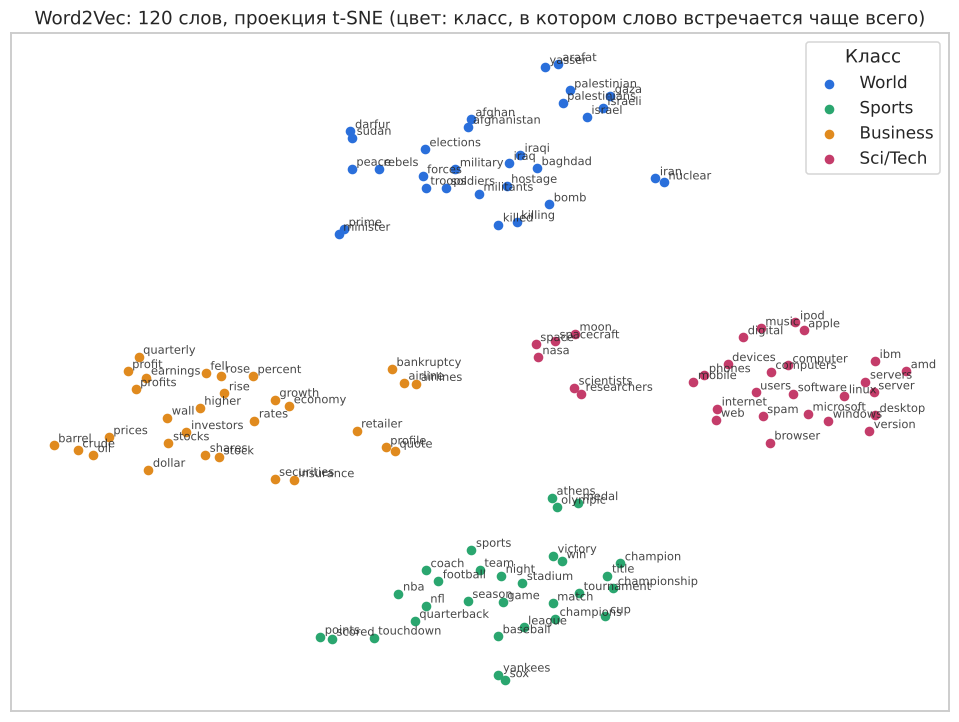

In [6]:
doc_count = defaultdict(lambda: np.zeros(4))
for toks, lab in zip(train_df['tokens'], train_df['label']):
    for t in set(toks):
        doc_count[t][lab - 1] += 1

STOP = set('the a an of to in and for on at with by from as is was are be that this it its his her he she they their '
           'has have had will would said says say new after over more about up out one two first'.split())
rows = []
for w, c in doc_count.items():
    n = c.sum()
    if n >= 300 and w in wv.key_to_index and w not in STOP and w.isalpha() and len(w) > 2 and c.max() / n >= 0.75:
        rows.append((w, int(n), int(c.argmax()) + 1, c.max() / n))
cand = pd.DataFrame(rows, columns=['word', 'docs', 'cls', 'share'])
cand['score'] = cand['share'] * np.log(cand['docs'])
sel = pd.concat([g.sort_values('score', ascending=False).head(30) for _, g in cand.groupby('cls')]).reset_index(drop=True)
print('Подходящих слов:', len(cand), ' выбрано для карты:', len(sel))

V = np.vstack([wv[w] for w in sel['word']])
Z = TSNE(n_components=2, perplexity=15, init='pca', learning_rate='auto', random_state=RANDOM_STATE).fit_transform(V)

colors = {1: '#2a6fdb', 2: '#2aa66f', 3: '#e08a1e', 4: '#c43c6a'}
fig, ax = plt.subplots(figsize=(11, 8))
for c in (1, 2, 3, 4):
    m = (sel['cls'] == c).values
    ax.scatter(Z[m, 0], Z[m, 1], c=colors[c], label=LABEL_MAP[c], s=28)
for (x, y), w in zip(Z, sel['word']):
    ax.annotate(w, (x, y), fontsize=7.5, alpha=0.85, xytext=(3, 2), textcoords='offset points')
ax.set_title('Word2Vec: 120 слов, проекция t-SNE (цвет: класс, в котором слово встречается чаще всего)')
ax.legend(title='Класс')
ax.set_xticks([]); ax.set_yticks([])
plt.show()

**Вывод по подшагу 1.2.** На карте видны четыре отдельные группы, которые совпадают с классами. Word2Vec обучался без меток, поэтому эта структура получена только из соседства слов в текстах. (Метки использовались лишь для отбора слов и раскраски, поэтому сильные слова каждого класса и должны оказаться в своих группах, но то, что они складываются в компактные облака, уже заслуга векторов.) Внутри групп тоже есть структура. Sports делится на командные виды (`nba`, `nfl`, `yankees`, `sox`, `quarterback`) и небольшую отдельную группу про Олимпиаду (`athens`, `olympic`, `medal`). В World отдельно лежат ближневосточные слова (`gaza`, `israel`, `palestinian`, `arafat`) и слова про военные конфликты в Ираке и Афганистане (`troops`, `militants`, `baghdad`). В Sci/Tech есть компьютерная часть (`software`, `linux`, `server`, `browser`) и космическая (`nasa`, `spacecraft`, `moon`), рядом с которой стоят `scientists` и `researchers`. В Business рядом оказываются `oil`, `crude`, `barrel`, `prices`, а отдельно отчётность (`profit`, `earnings`, `quarterly`) и авиакомпании (`airlines`, `bankruptcy`).

Оговорка: t-SNE сохраняет близость соседей, но расстояния между далёкими группами и их взаимное положение на плоскости интерпретировать нельзя. И на карте только слова, наиболее характерные для своего класса. Общие слова, по которым классы смешиваются (в третьей работе это Business и Sci/Tech), сюда нарочно не попали.

## 2. Baseline: усреднение векторов слов и логистическая регрессия

Для каждого документа беру векторы всех его слов, которые есть в словаре Word2Vec, и усредняю их (mean pooling). Получается один плотный вектор длиной 100. Порядок слов при этом теряется, как и в мешке слов, но вместо разреженного вектора на 42 тысячи признаков получаем компактный вектор, в котором близкие по смыслу слова вносят похожий вклад.

На этих векторах обучаю логистическую регрессию. Параметр регуляризации `C` подбираю кросс-валидацией на Train (3 фолда, macro F1), как в третьей работе.

In [7]:
def doc_vec(tokens):
    vecs = [wv[t] for t in tokens if t in wv.key_to_index]
    return np.mean(vecs, axis=0) if vecs else np.zeros(wv.vector_size, dtype=np.float32)

t0 = time.time()
Xtr_w2v = np.vstack(train_df['tokens'].map(doc_vec))
Xte_w2v = np.vstack(test_df['tokens'].map(doc_vec))
pool_time = time.time() - t0
y_train = train_df['label'].values
y_test = test_df['label'].values
print('Матрицы признаков:', Xtr_w2v.shape, Xte_w2v.shape, f' (усреднение {pool_time:.1f} с)')
print('Документов без единого известного слова в Train:', int((np.abs(Xtr_w2v).sum(axis=1) == 0).sum()))

lr_search = GridSearchCV(LogisticRegression(max_iter=1000), {'C': [0.1, 1, 10]},
                         scoring='f1_macro', cv=3, n_jobs=1)
lr_search.fit(Xtr_w2v, y_train)
print(pd.DataFrame({'C': lr_search.cv_results_['param_C'], 'macro F1 (CV)': lr_search.cv_results_['mean_test_score'].round(4)}).to_string(index=False))
print('Лучшее:', lr_search.best_params_)

t0 = time.time()
lr = LogisticRegression(C=lr_search.best_params_['C'], max_iter=1000).fit(Xtr_w2v, y_train)
lr_time = time.time() - t0
pred_lr = lr.predict(Xte_w2v)
results['Логистическая регрессия'] = {**evaluate(y_test, pred_lr), 'time': lr_time, 'prep': w2v_time + pool_time,
                                      'arch': 'mean pooling Word2Vec (100)', 'note': 'C подобран CV'}
print(f'\nОбучение за {lr_time:.1f} с')
print(pd.Series(results['Логистическая регрессия']).loc[['precision', 'recall', 'f1', 'accuracy']].round(4).to_string())

Матрицы признаков: (96000, 100) (24000, 100)  (усреднение 5.7 с)
Документов без единого известного слова в Train: 0


   C  macro F1 (CV)
 0.1         0.8895
 1.0         0.8911
10.0         0.8908
Лучшее: {'C': 1}



Обучение за 2.0 с
precision    0.8935
recall       0.8937
f1           0.8935
accuracy     0.8937


**Вывод по шагу 2.** Логистическая регрессия на усреднённых векторах Word2Vec дала macro F1 0,8935 (Accuracy 0,8937). Это заметно ниже, чем LinearSVC на TF-IDF из третьей работы (0,9225), на 2,9 процентного пункта. Параметр `C` почти не влияет (по CV 0,8895-0,8911, лучшее `C=1`). Вероятная причина невысокого качества в том, что усреднение размывает информацию: несколько характерных слов документа (имена, названия компаний) смешиваются в одном векторе длиной 100 с десятками служебных и общих слов, а TF-IDF сохраняет каждое слово отдельным признаком и даёт редким словам больший вес. Обучение самой регрессии заняло 2 с, но подготовка признаков (обучение Word2Vec плюс усреднение) заняла около 168 с. Это baseline: он показывает, чего можно добиться, если просто заменить мешок слов плотными векторами.

## 3. BiLSTM: static и dynamic Embedding

Двунаправленная LSTM читает последовательность слов в обе стороны, поэтому учитывает порядок слов и контекст, чего не делают ни мешок слов, ни усреднение. Архитектура:

1. слой Embedding (слово в индексе превращается в вектор длиной 100);
2. BiLSTM со 128 нейронами в каждом направлении (на выходе вектор длиной 256 на каждое слово);
3. max-pooling по времени: для каждого из 256 признаков берётся максимум по словам документа (дополняющие `<pad>` не учитываются);
4. Dropout 0,3 и линейный слой на 4 класса.

Два режима слоя Embedding:
- **Static**: веса инициализируются матрицей Word2Vec из шага 1 и замораживаются (`requires_grad=False`), то есть сеть пользуется готовыми векторами и не меняет их.
- **Dynamic**: те же размеры, но случайная инициализация, и вектора обучаются вместе с сетью с нуля.

Словарь для обоих режимов один и тот же: слова из словаря Word2Vec (26 тысяч слов), остальные заменяются на `<unk>`. Документы обрезаются или дополняются до 64 токенов (в среднем 38, 98% документов короче).

In [8]:
MAXLEN = 64
itos = ['<pad>', '<unk>'] + list(wv.index_to_key)
stoi = {w: i for i, w in enumerate(itos)}

def encode(tokens):
    ids = [stoi.get(t, 1) for t in tokens[:MAXLEN]]
    return ids + [0] * (MAXLEN - len(ids))

X_all = torch.tensor([encode(t) for t in train_df['tokens']])
y_all = torch.tensor(y_train - 1)
X_te = torch.tensor([encode(t) for t in test_df['tokens']])
y_te = torch.tensor(y_test - 1)

n_tokens = sum(min(len(t), MAXLEN) for t in train_df['tokens'])
n_unk = int((X_all == 1).sum())
print('Размер словаря сети:', len(itos))
print(f'Доля токенов <unk> в Train: {n_unk / n_tokens:.2%}')
print(f'Документов длиннее {MAXLEN} токенов (обрезаются): {(train_df["tokens"].map(len) > MAXLEN).mean():.1%}')

# validation: 10% Train, стратифицированно; по нему работает Early Stopping
idx_tr, idx_val = train_test_split(np.arange(len(X_all)), test_size=0.1, random_state=RANDOM_STATE,
                                   stratify=y_train)
X_tr, y_tr = X_all[idx_tr], y_all[idx_tr]
X_val, y_val = X_all[idx_val], y_all[idx_val]
print('Обучающая часть:', len(X_tr), ' validation:', len(X_val), ' test:', len(X_te))

emb_matrix = np.zeros((len(itos), wv.vector_size), dtype=np.float32)
emb_matrix[2:] = wv.vectors
emb_matrix[1] = wv.vectors.mean(axis=0)   # <unk> получает средний вектор

Размер словаря сети: 26090
Доля токенов <unk> в Train: 2.15%
Документов длиннее 64 токенов (обрезаются): 1.7%
Обучающая часть: 86400  validation: 9600  test: 24000


In [9]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, static):
        super().__init__()
        if static:
            self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=True, padding_idx=0)
        else:
            self.emb = nn.Embedding(len(itos), wv.vector_size, padding_idx=0)
        self.rnn = nn.LSTM(wv.vector_size, 128, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(256, 4)

    def forward(self, x):
        mask = (x != 0).unsqueeze(-1)
        h, _ = self.rnn(self.emb(x))
        h = h.masked_fill(~mask, -1e9).max(dim=1).values
        return self.fc(self.drop(h))

for static in (True, False):
    m = BiLSTMClassifier(static)
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'{"Static " if static else "Dynamic"}: параметров всего {total:,}, обучаемых {trainable:,}')

Static : параметров всего 2,845,548, обучаемых 236,548
Dynamic: параметров всего 2,845,548, обучаемых 2,845,548


**Что получилось в ячейках шага 3.** В словаре сети 26 090 слов (словарь Word2Vec плюс `<pad>` и `<unk>`), на `<unk>` приходится 2,15% токенов Train, а обрезаются только 1,7% документов. Обучающая часть 86 400 документов, validation 9 600, Test прежний, 24 000. Всего в модели 2 845 548 параметров, из них 2 609 000 (26 090 слов умножить на 100) находятся в слое Embedding. В режиме static они заморожены, и обучаются только 236 548 параметров (LSTM и линейный слой), в режиме dynamic обучаются все 2 845 548. Разницу в числе обучаемых параметров, почти в 12 раз, стоит учитывать при сравнении двух режимов.

## 4. Оценка RNN: графики и Early Stopping

Обучаю обе сети оптимизатором Adam (`lr=2e-3`, батч 256), максимум 8 эпох. После каждой эпохи считаю Loss и macro F1 на обучающей части и на validation. Early Stopping работает по validation Loss: если за 2 эпохи подряд он не улучшился, обучение останавливается, а в модель возвращаются веса лучшей эпохи. Обучающие метрики считаются по ходу эпохи с включённым Dropout, поэтому они немного занижены относительно честной оценки.

In [10]:
@torch.no_grad()
def predict_logits(model, X, bs=1024):
    model.eval()
    return torch.cat([model(X[i:i + bs].to(DEVICE)).cpu() for i in range(0, len(X), bs)])


def train_rnn(static, max_epochs=8, patience=2, lr=2e-3, bs=256):
    torch.manual_seed(RANDOM_STATE)
    model = BiLSTMClassifier(static).to(DEVICE)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    hist = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': []}
    best_val, best_state, best_epoch, bad = float('inf'), None, 0, 0
    t0 = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(X_tr))
        loss_sum, preds, labels = 0.0, [], []
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            xb, yb = X_tr[idx].to(DEVICE), y_tr[idx].to(DEVICE)
            opt.zero_grad()
            logits = model(xb)
            loss = nn.functional.cross_entropy(logits, yb)
            loss.backward()
            opt.step()
            loss_sum += loss.item() * len(idx)
            preds.append(logits.argmax(1).cpu())
            labels.append(yb.cpu())
        tr_loss = loss_sum / len(X_tr)
        tr_f1 = f1_score(torch.cat(labels).numpy(), torch.cat(preds).numpy(), average='macro')
        val_logits = predict_logits(model, X_val)
        val_loss = nn.functional.cross_entropy(val_logits, y_val).item()
        val_f1 = f1_score(y_val.numpy(), val_logits.argmax(1).numpy(), average='macro')
        for k, v in zip(hist, (tr_loss, val_loss, tr_f1, val_f1)):
            hist[k].append(v)
        print(f'эпоха {epoch}: train loss {tr_loss:.4f} F1 {tr_f1:.4f} | val loss {val_loss:.4f} F1 {val_f1:.4f} | {time.time() - t0:.0f} с')
        if val_loss < best_val - 1e-4:
            best_val, best_epoch, bad = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                print(f'Early Stopping: validation loss не улучшается {patience} эпохи подряд, лучшая эпоха {best_epoch}')
                break
    model.load_state_dict(best_state)
    return model, hist, best_epoch, time.time() - t0


rnn = {}
for static in (True, False):
    name = 'BiLSTM static' if static else 'BiLSTM dynamic'
    print('=' * 20, name, '=' * 20)
    rnn[name] = train_rnn(static)

==================== BiLSTM static ====================


эпоха 1: train loss 0.3879 F1 0.8675 | val loss 0.3035 F1 0.8981 | 97 с


эпоха 2: train loss 0.2879 F1 0.9014 | val loss 0.2766 F1 0.9049 | 193 с


эпоха 3: train loss 0.2666 F1 0.9077 | val loss 0.2620 F1 0.9105 | 291 с


эпоха 4: train loss 0.2510 F1 0.9123 | val loss 0.2520 F1 0.9113 | 389 с


эпоха 5: train loss 0.2386 F1 0.9163 | val loss 0.2438 F1 0.9158 | 484 с


... (4 outputs left out)

эпоха 2: train loss 0.2760 F1 0.9070 | val loss 0.2866 F1 0.9036 | 199 с


эпоха 3: train loss 0.2102 F1 0.9287 | val loss 0.2818 F1 0.9067 | 295 с


эпоха 4: train loss 0.1616 F1 0.9455 | val loss 0.2844 F1 0.9081 | 404 с


эпоха 5: train loss 0.1230 F1 0.9587 | val loss 0.3089 F1 0.9051 | 516 с
Early Stopping: validation loss не улучшается 2 эпохи подряд, лучшая эпоха 3


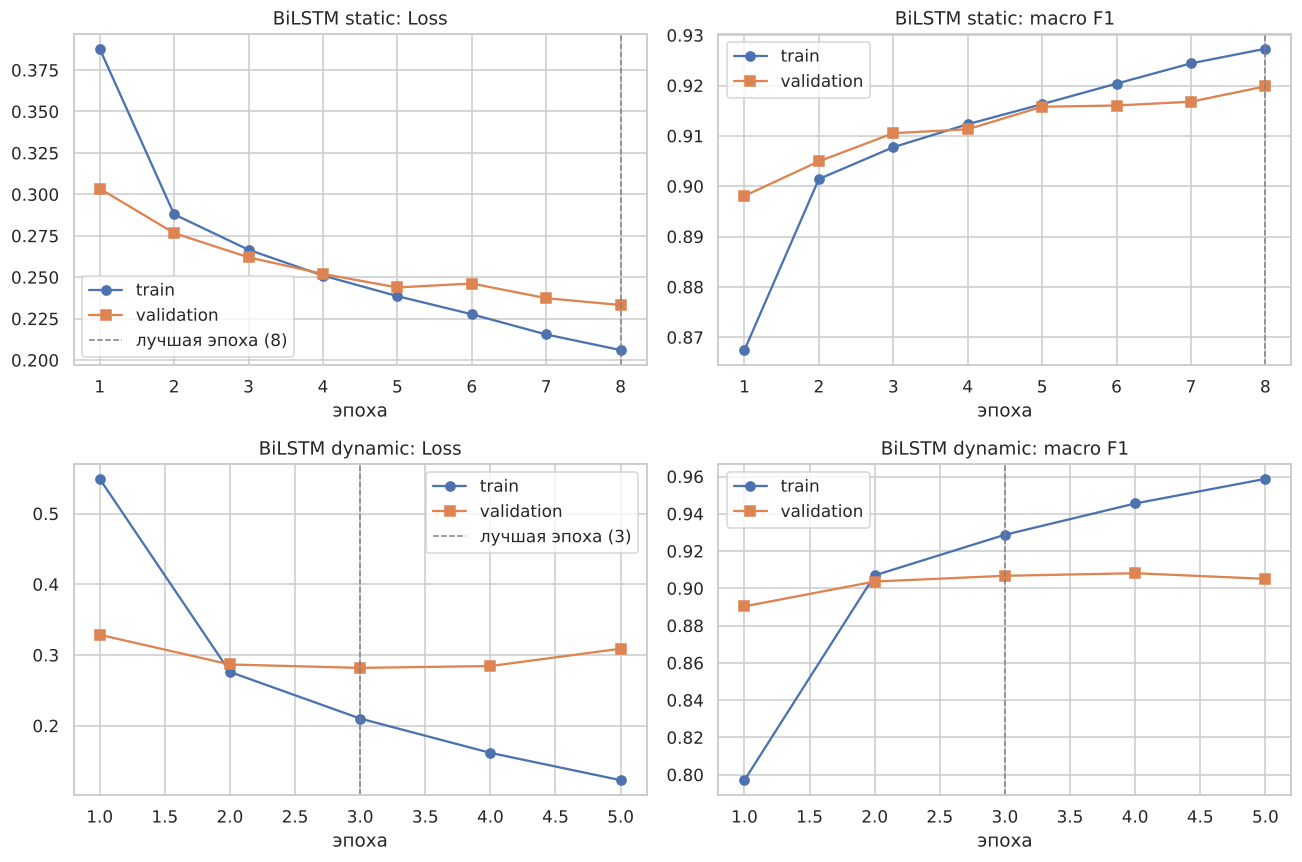

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False)
for row, name in enumerate(rnn):
    model, hist, best_epoch, _ = rnn[name]
    ep = range(1, len(hist['train_loss']) + 1)
    axes[row, 0].plot(ep, hist['train_loss'], 'o-', label='train')
    axes[row, 0].plot(ep, hist['val_loss'], 's-', label='validation')
    axes[row, 0].axvline(best_epoch, color='gray', ls='--', lw=1, label=f'лучшая эпоха ({best_epoch})')
    axes[row, 0].set_title(f'{name}: Loss'); axes[row, 0].set_xlabel('эпоха'); axes[row, 0].legend()
    axes[row, 1].plot(ep, hist['train_f1'], 'o-', label='train')
    axes[row, 1].plot(ep, hist['val_f1'], 's-', label='validation')
    axes[row, 1].axvline(best_epoch, color='gray', ls='--', lw=1)
    axes[row, 1].set_title(f'{name}: macro F1'); axes[row, 1].set_xlabel('эпоха'); axes[row, 1].legend()
plt.tight_layout()
plt.show()

In [12]:
rows = []
for name in rnn:
    model, hist, best_epoch, train_time = rnn[name]
    pred = predict_logits(model, X_te).argmax(1).numpy() + 1
    m = evaluate(y_test, pred)
    results[name] = {**m, 'time': train_time, 'prep': w2v_time,
                     'arch': 'BiLSTM (128x2) + Word2Vec, ' + ('заморожен' if 'static' in name else 'обучается'),
                     'note': f'лучшая эпоха {best_epoch} из {len(hist["train_loss"])}'}
    rows.append({'модель': name, 'Precision': m['precision'], 'Recall': m['recall'], 'F1': m['f1'],
                 'Accuracy': m['accuracy'], 'лучшая эпоха': best_epoch, 'эпох всего': len(hist['train_loss']),
                 'время обучения, с': round(train_time)})
display(pd.DataFrame(rows).set_index('модель').round(4))

best_name = max(rnn, key=lambda n: results[n]['f1'])
pred_best = predict_logits(rnn[best_name][0], X_te).argmax(1).numpy() + 1
print(f'Отчёт по классам для лучшей сети ({best_name}):')
print(classification_report(y_test, pred_best, target_names=[LABEL_MAP[i] for i in (1, 2, 3, 4)], digits=4))

,Precision,Recall,F1,Accuracy,лучшая эпоха,эпох всего,"время обучения, с"
модель,,,,,,,
BiLSTM static,0.9254,0.9246,0.9244,0.9246,8,8,768
BiLSTM dynamic,0.9110,0.9104,0.9105,0.9104,3,5,516


Отчёт по классам для лучшей сети (BiLSTM static):
              precision    recall  f1-score   support

       World     0.9449    0.9118    0.9281      6000
      Sports     0.9642    0.9843    0.9742      6000
    Business     0.9186    0.8672    0.8921      6000
    Sci/Tech     0.8737    0.9350    0.9033      6000

    accuracy                         0.9246     24000
   macro avg     0.9254    0.9246    0.9244     24000
weighted avg     0.9254    0.9246    0.9244     24000



**Вывод по шагу 4.** Результаты на Test:

| Режим | Precision | Recall | Macro F1 | Эпох | Лучшая эпоха | Время обучения |
|---|---|---|---|---|---|---|
| BiLSTM static | 0,9254 | 0,9246 | 0,9244 | 8 | 8 | 768 с |
| BiLSTM dynamic | 0,9110 | 0,9104 | 0,9105 | 5 | 3 | 516 с |

Static лучше dynamic на 1,4 процентного пункта, и по графикам видно почему. У dynamic быстро растёт разрыв между train и validation: к пятой эпохе F1 на обучающей части 0,959, а на validation 0,905, и validation loss после третьей эпохи растёт (0,282, затем 0,284, затем 0,309). Это переобучение, и Early Stopping останавливает обучение на пятой эпохе и возвращает веса третьей. Вероятная причина в том, что dynamic учит 2,8 миллиона параметров, из них 2,6 миллиона векторы слов, на 86 тысячах документов, и подстраивается под обучающие данные. У static кривые train и validation идут рядом, а замороженные векторы Word2Vec, судя по результату, играют роль готовой регуляризации.

Важная оговорка про static: Early Stopping у него не сработал. Validation loss к восьмой эпохе всё ещё снижался (0,2332, на шестой эпохе был небольшой подъём, но не два раза подряд), и обучение остановилось из-за ограничения в 8 эпох. С бо́льшим лимитом метрики могли бы вырасти ещё немного, это я не проверяла.

По классам static (F1): Sports 0,974, World 0,928, Sci/Tech 0,903, Business 0,892. Слабые места те же, что у SVM в третьей работе: Business и Sci/Tech.

Сравнение с SVM: static 0,9244 против 0,9225, разница около 0,002. Для одного запуска на 24 000 документах это сопоставимо с погрешностью оценки (порядка 0,002), поэтому я считаю качество практически равным, а не доказанным преимуществом рекуррентной сети.

## 5. Выбор предобученного трансформера

В задании в качестве примера названы `rubert-tiny2` и `rubert-base-cased`, но они обучены на русском языке. Наш датасет английский, поэтому нужна английская модель. Беру **`distilbert-base-uncased`** из Hugging Face: это уменьшенная версия BERT (6 слоёв вместо 12, около 66 млн параметров, примерно вдвое быстрее BERT-base при сопоставимом качестве), обученная на английских текстах без учёта регистра. Для нашей задачи регистр не критичен, а скорость важна: дообучение идёт на CPU или одном небольшом GPU. Чтобы взять другую модель (`bert-base-uncased`, `roberta-base`), достаточно поменять переменную `MODEL_NAME`.

Токенизатор трансформера работает с «сырым» текстом: ему нужны регистр, пунктуация и слова целиком, поэтому очистку из шага 0 (удаление знаков препинания, замена чисел) здесь не применяю. Только декодирую HTML-сущности и убираю теги.

In [ ]:
MODEL_NAME = 'distilbert-base-uncased'
N_PER_CLASS = 4000      # сбалансированная подвыборка Train: 4000 документов на класс (16 000 всего)
N_VAL_PER_CLASS = 500   # validation для выбора лучшей эпохи
MAX_LEN_BERT = 64
BERT_EPOCHS = 3
BERT_LR = 5e-5
BERT_BS = 32

RE_ENT = re.compile(r'(?<![&\w])(#\d+|#x[0-9a-fA-F]+|quot|amp|lt|gt|apos);')
def light_clean(text):
    text = RE_ENT.sub(r'&\1;', text)
    text = html.unescape(text)
    text = re.sub(r'<[^>]+>', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

parts = [train_df[train_df['label'] == l].sample(N_PER_CLASS + N_VAL_PER_CLASS, random_state=RANDOM_STATE) for l in (1, 2, 3, 4)]
bert_train = pd.concat([p.iloc[:N_PER_CLASS] for p in parts]).sample(frac=1, random_state=RANDOM_STATE)
bert_val = pd.concat([p.iloc[N_PER_CLASS:] for p in parts]).sample(frac=1, random_state=RANDOM_STATE)
print('Подвыборка для fine-tuning:', len(bert_train), ' validation:', len(bert_val), ' test (весь):', len(test_df))
print(bert_train['category'].value_counts().to_dict())
print('Пример текста для модели:', light_clean(bert_train['text'].iloc[0])[:150])
print('GPU доступен:', torch.cuda.is_available())

## 6. Fine-Tuning трансформера

`AutoModelForSequenceClassification` берёт предобученный DistilBERT и добавляет поверх него классификационную голову: линейный слой (с небольшим слоем и Dropout перед ним) на 4 класса, вход которого берётся из представления первого токена `[CLS]`. Затем дообучаются все веса, и encoder, и голова, на нашей подвыборке. Использую класс `Trainer` из библиотеки transformers: он сам делает батчи, считает loss, обновляет веса, оценивает модель на validation после каждой эпохи и в конце загружает лучшую по macro F1 эпоху. Скорость обучения 5e-5, три эпохи, батч 32. На GPU включается смешанная точность (fp16).

Обучение идёт на подвыборке в 16 000 документов, как разрешено в задании, а оценка на всём Test (24 000), чтобы метрики были сравнимы с остальными моделями.

In [ ]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, Trainer,
                          TrainingArguments, DataCollatorWithPadding)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=4)
print('Параметров в модели:', f'{sum(p.numel() for p in bert_model.parameters()):,}')


class TextDS(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer([light_clean(t) for t in texts], truncation=True, max_length=MAX_LEN_BERT)
        self.labels = list(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item['labels'] = int(self.labels[i]) - 1
        return item

ds_train = TextDS(bert_train['text'], bert_train['label'])
ds_val = TextDS(bert_val['text'], bert_val['label'])
ds_test = TextDS(test_df['text'], test_df['label'])


def compute_metrics(eval_pred):
    pred = eval_pred.predictions.argmax(-1)
    m = evaluate(eval_pred.label_ids, pred)
    return {'precision': m['precision'], 'recall': m['recall'], 'f1': m['f1'], 'accuracy': m['accuracy']}


args = TrainingArguments(
    output_dir='bert_out', num_train_epochs=BERT_EPOCHS, per_device_train_batch_size=BERT_BS,
    per_device_eval_batch_size=128, learning_rate=BERT_LR, weight_decay=0.01, warmup_ratio=0.1,
    eval_strategy='epoch', save_strategy='epoch', save_total_limit=1,
    load_best_model_at_end=True, metric_for_best_model='f1',
    logging_strategy='epoch', report_to='none', fp16=torch.cuda.is_available(), seed=RANDOM_STATE)

trainer = Trainer(model=bert_model, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics)

In [ ]:
t0 = time.time()
trainer.train()
bert_time = time.time() - t0
print(f'Fine-tuning занял {bert_time:.0f} с')

log = pd.DataFrame(trainer.state.log_history)
epoch_table = pd.concat([
    log.dropna(subset=['loss'])[['epoch', 'loss']].rename(columns={'loss': 'train loss'}).set_index('epoch'),
    log.dropna(subset=['eval_loss'])[['epoch', 'eval_loss', 'eval_f1']].rename(
        columns={'eval_loss': 'val loss', 'eval_f1': 'val macro F1'}).set_index('epoch')], axis=1)
display(epoch_table.round(4))

In [ ]:
out = trainer.predict(ds_test)
pred_bert = out.predictions.argmax(-1) + 1
m = evaluate(y_test, pred_bert)
results['BERT fine-tuning'] = {**m, 'time': bert_time, 'prep': 0.0,
                               'arch': f'{MODEL_NAME} + линейная голова',
                               'note': f'{len(bert_train)} док. для обучения, {BERT_EPOCHS} эпохи'}
print(pd.Series(m).round(4).to_string())
print()
print(classification_report(y_test, pred_bert, target_names=[LABEL_MAP[i] for i in (1, 2, 3, 4)], digits=4))

## 7. Сводный бенчмарк

Чтобы в таблице были и классические модели из третьей работы, заново обучаю их здесь на тех же данных: TF-IDF (словарь только на Train, `min_df=2`, `sublinear_tf=True`) и два классификатора с лучшими параметрами, которые я нашла там кросс-валидацией: Naive Bayes с `alpha=0.1` и LinearSVC с `C=0.3`. Время указываю отдельно для подготовки признаков (TF-IDF, обучение Word2Vec) и для обучения самого классификатора.

In [17]:
t0 = time.time()
tfidf = TfidfVectorizer(tokenizer=str.split, preprocessor=None, lowercase=False, token_pattern=None,
                        min_df=2, sublinear_tf=True)
Xtr_tfidf = tfidf.fit_transform(train_df['text_clean'])
Xte_tfidf = tfidf.transform(test_df['text_clean'])
tfidf_time = time.time() - t0

for name, clf, note in [('Naive Bayes', MultinomialNB(alpha=0.1), 'alpha=0.1'),
                        ('LinearSVC', LinearSVC(C=0.3, class_weight='balanced'), 'C=0.3')]:
    t0 = time.time()
    clf.fit(Xtr_tfidf, y_train)
    fit_time = time.time() - t0
    m = evaluate(y_test, clf.predict(Xte_tfidf))
    results[name] = {**m, 'time': fit_time, 'prep': tfidf_time,
                     'arch': f'TF-IDF ({Xtr_tfidf.shape[1]} признаков)', 'note': note + ', параметры из лабораторной 3'}
    print(f'{name}: F1 {m["f1"]:.4f}, обучение {fit_time:.2f} с (TF-IDF {tfidf_time:.1f} с)')

Naive Bayes: F1 0.9086, обучение 0.03 с (TF-IDF 2.3 с)


LinearSVC: F1 0.9225, обучение 3.88 с (TF-IDF 2.3 с)


In [18]:
ORDER = ['Naive Bayes', 'LinearSVC', 'Логистическая регрессия', 'BiLSTM static', 'BiLSTM dynamic', 'BERT fine-tuning']
rows = []
for name in ORDER:
    r = results.get(name)
    if r is None:
        rows.append({'Модель': name, 'Векторизация / Архитектура': 'не запускалось', 'Разметка / Особенности': 'выполни ячейки шага 6',
                     'Precision': np.nan, 'Recall': np.nan, 'F1-Score': np.nan, 'Accuracy': np.nan,
                     'Подготовка, с': np.nan, 'Время обучения, с': np.nan})
        continue
    rows.append({'Модель': name, 'Векторизация / Архитектура': r['arch'], 'Разметка / Особенности': r['note'],
                 'Precision': r['precision'], 'Recall': r['recall'], 'F1-Score': r['f1'], 'Accuracy': r['accuracy'],
                 'Подготовка, с': r['prep'], 'Время обучения, с': r['time']})
bench = pd.DataFrame(rows).set_index('Модель')
display(bench.round({'Precision': 4, 'Recall': 4, 'F1-Score': 4, 'Accuracy': 4, 'Подготовка, с': 1, 'Время обучения, с': 1}))

,Векторизация / Архитектура,Разметка / Особенности,Precision,Recall,F1-Score,Accuracy,"Подготовка, с","Время обучения, с"
Модель,,,,,,,,
Naive Bayes,TF-IDF (42500 признаков),"alpha=0.1, параметры из лабораторной 3",0.9087,0.9088,0.9086,0.9088,2.3,0.0
LinearSVC,TF-IDF (42500 признаков),"C=0.3, параметры из лабораторной 3",0.9226,0.9227,0.9225,0.9227,2.3,3.9
Логистическая регрессия,mean pooling Word2Vec (100),C подобран CV,0.8935,0.8937,0.8935,0.8937,167.7,2.0
BiLSTM static,"BiLSTM (128x2) + Word2Vec, заморожен",лучшая эпоха 8 из 8,0.9254,0.9246,0.9244,0.9246,162.0,768.3
BiLSTM dynamic,"BiLSTM (128x2) + Word2Vec, обучается",лучшая эпоха 3 из 5,0.9110,0.9104,0.9105,0.9104,162.0,515.6
BERT fine-tuning,не запускалось,выполни ячейки шага 6,NaN,NaN,NaN,NaN,NaN,NaN


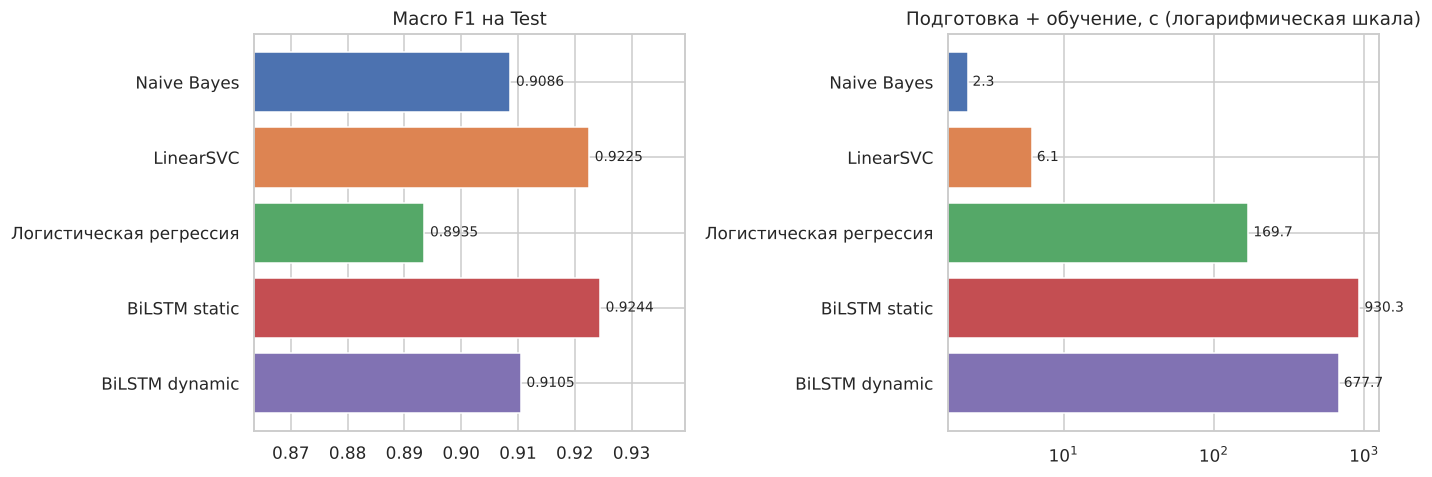

In [19]:
done = bench.dropna(subset=['F1-Score'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
palette = sns.color_palette('deep', len(done))
axes[0].barh(done.index, done['F1-Score'], color=palette)
axes[0].set_xlim(done['F1-Score'].min() - 0.03, min(1.0, done['F1-Score'].max() + 0.015))
for i, v in enumerate(done['F1-Score']):
    axes[0].text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=9)
axes[0].invert_yaxis(); axes[0].set_title('Macro F1 на Test')
total_time = done['Подготовка, с'] + done['Время обучения, с']
axes[1].barh(done.index, total_time, color=palette)
axes[1].set_xscale('log'); axes[1].invert_yaxis()
axes[1].set_title('Подготовка + обучение, с (логарифмическая шкала)')
for i, v in enumerate(total_time):
    axes[1].text(v * 1.08, i, f'{v:.1f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

## 8. Итоговый вывод

**Итоговый вывод.** Сводка по macro F1 на Test: BiLSTM static 0,9244, LinearSVC 0,9225, BiLSTM dynamic 0,9105, Naive Bayes 0,9086, логистическая регрессия на усреднённых Word2Vec 0,8935 (строка с трансформером заполняется после запуска шага 6, см. ниже).

**Соотношение ресурсов и качества.** Все измерения на CPU с двумя ядрами, и на GPU времена нейросетей были бы существенно меньше. LinearSVC на TF-IDF обходится примерно в 6 секунд (2,3 с на TF-IDF и 3,9 с на обучение) и даёт 0,9225. BiLSTM static даёт на 0,002 больше, но требует около 930 секунд (162 с на Word2Vec и 768 с на обучение), то есть примерно в 150 раз дольше, плюс нужны PyTorch, подбор архитектуры и контроль переобучения. Эта разница в качестве лежит в пределах погрешности, поэтому на нашем датасете выигрыша сложной модели над классической я не вижу. Naive Bayes проигрывает SVM 1,4 процентного пункта, но обучается за сотые доли секунды, и это самый дешёвый вариант. Рекуррентная сеть с обучаемым Embedding (dynamic) хуже SVM на 1,2 процентного пункта и дороже его примерно в 100 раз: данных (86 тысяч документов) не хватает, чтобы выучить хорошие векторы слов «с нуля», она переобучается. А замороженные векторы Word2Vec из static решают эту проблему.

**Почему классические методы здесь так сильны.** Задача определения тематики новости в основном решается по ключевым словам: `oil`, `nasa`, `baseball`, `iraq` почти однозначно называют класс, а мешок слов с TF-IDF как раз сохраняет каждое такое слово отдельным признаком. Тексты короткие (в среднем 38 слов), порядок слов и дальний контекст почти не нужны, а BiLSTM именно эти возможности и добавляет. Усреднение векторов в baseline, наоборот, размывает ключевые слова и проигрывает SVM почти три процентных пункта. У SVM и у BiLSTM static слабые классы одни и те же, Business и Sci/Tech. В третьей работе я разбирала причины таких ошибок: размытая граница классов и спорная разметка. Их не исправить одной сменой модели без дополнительной информации.

**Трансформер.** (Этот абзац нужно дополнить после запуска ячеек шага 6.) Впиши F1 и время обучения дообученной модели из последней таблицы и сравни с SVM (0,9225) и BiLSTM static (0,9244). Если трансформер выше, укажи, на сколько и какой ценой по времени (подготовка и обучение на 16 000 документах), и объясни выигрыш тем, что предобученная на огромном корпусе модель знает значения слов и контекст лучше, чем Word2Vec, обученный на наших 96 тысячах документов. Если разница небольшая, объясни это тем же, что и выше: тема новости определяется ключевыми словами, и сложная модель мало что добавляет.

**Общий итог.** Для задачи тематической классификации новостей AG News разумный выбор по соотношению качества и затрат это TF-IDF с линейной моделью: он даёт качество около 0,92 за секунды, а нейросети на CPU дают то же качество за минуты и требуют заметно больше усилий. Нейросетевые подходы оправданы, когда нужен смысловой контекст (например, тональность, где важен порядок слов и отрицания) или когда есть GPU и много данных.